In [1]:
print("This program run by Manthan Mishra")
print("Roll No.:-36")

This program run by Manthan Mishra
Roll No.:-36


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")


In [3]:
df = pd.read_csv("auto-mpg.xls")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu,NaN,NaN,NaN
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320,NaN,NaN,NaN
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite,NaN,NaN,NaN
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst,NaN,NaN,NaN
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino,NaN,NaN,NaN


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (398, 12)

Column Names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']

Data Types:
mpg             float64
cylinders         int64
displacement    float64
horsepower          str
weight            int64
acceleration    float64
model year        int64
origin            int64
car name            str
Unnamed: 9      float64
Unnamed: 10     float64
Unnamed: 11     float64
dtype: object

Missing Values:
mpg               0
cylinders         0
displacement      0
horsepower        0
weight            0
acceleration      0
model year        0
origin            0
car name          0
Unnamed: 9      398
Unnamed: 10     398
Unnamed: 11     398
dtype: int64


In [5]:
# Convert horsepower to numeric
# Invalid values such as '?' become NaN
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")

# Remove rows with missing horsepower or mpg
df = df.dropna(subset=["horsepower", "mpg"])

print("Shape after removing missing values:", df.shape)

df.head()

Shape after removing missing values: (392, 12)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu,NaN,NaN,NaN
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320,NaN,NaN,NaN
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite,NaN,NaN,NaN
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst,NaN,NaN,NaN
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino,NaN,NaN,NaN


In [6]:
# Input feature
X = df[["horsepower"]]

# Target variable
y = df["mpg"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (392, 1)
y shape: (392,)


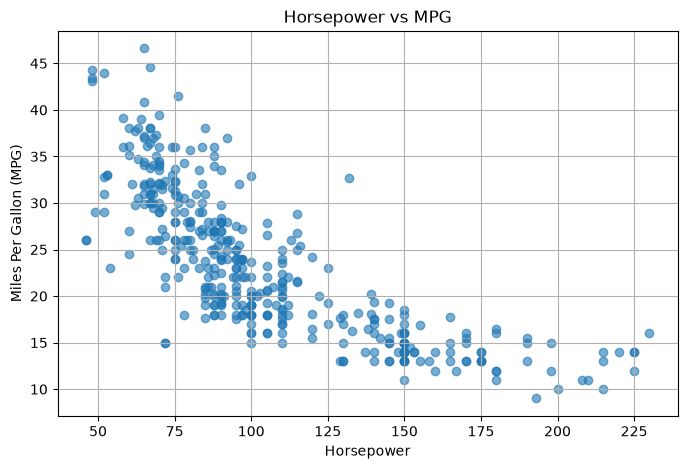

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, alpha=0.6)

plt.xlabel("Horsepower")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Horsepower vs MPG")

plt.grid(True)
plt.show()

In [8]:
# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 313
Testing samples: 79


In [9]:
degrees = [1, 2, 3, 5, 7, 10]

train_mse = []
test_mse = []
test_r2 = []

models = {}

for degree in degrees:
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_poly)
    X_test_scaled = scaler.transform(X_test_poly)

    model = LinearRegression()

    model.fit(X_train_scaled, y_train)

    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    mse_train = mean_squared_error(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)

    r2_test = r2_score(y_test, y_test_pred)

    train_mse.append(mse_train)
    test_mse.append(mse_test)
    test_r2.append(r2_test)

    models[degree] = {
        "poly": poly,
        "scaler": scaler,
        "model": model
    }

    print(
        f"Degree {degree}: "
        f"Train MSE = {mse_train:.4f}, "
        f"Test MSE = {mse_test:.4f}, "
        f"Test R² = {r2_test:.4f}"
    )

Degree 1: Train MSE = 24.4752, Test MSE = 22.1532, Test R² = 0.5660
Degree 2: Train MSE = 19.2046, Test MSE = 18.4170, Test R² = 0.6392
Degree 3: Train MSE = 19.1438, Test MSE = 18.4603, Test R² = 0.6383
Degree 5: Train MSE = 18.6440, Test MSE = 17.8770, Test R² = 0.6497
Degree 7: Train MSE = 18.4543, Test MSE = 17.0438, Test R² = 0.6661
Degree 10: Train MSE = 18.4137, Test MSE = 17.1858, Test R² = 0.6633


In [10]:
results = pd.DataFrame({
    "Degree": degrees,
    "Train MSE": train_mse,
    "Test MSE": test_mse,
    "Test R²": test_r2
})

results

,Degree,Train MSE,Test MSE,Test R²
0,1,24.475168,22.153237,0.565968
1,2,19.204614,18.416968,0.639170
2,3,19.143788,18.460267,0.638322
3,5,18.644029,17.877014,0.649749
4,7,18.454341,17.043847,0.666073
5,10,18.413669,17.185780,0.663292


In [11]:
# Find degree having minimum test MSE
optimal_index = np.argmin(test_mse)
optimal_degree = degrees[optimal_index]

print("Optimal Polynomial Degree:", optimal_degree)
print("Minimum Test MSE:", test_mse[optimal_index])
print("Test R²:", test_r2[optimal_index])

Optimal Polynomial Degree: 7
Minimum Test MSE: 17.04384744005377
Test R²: 0.666072635574007


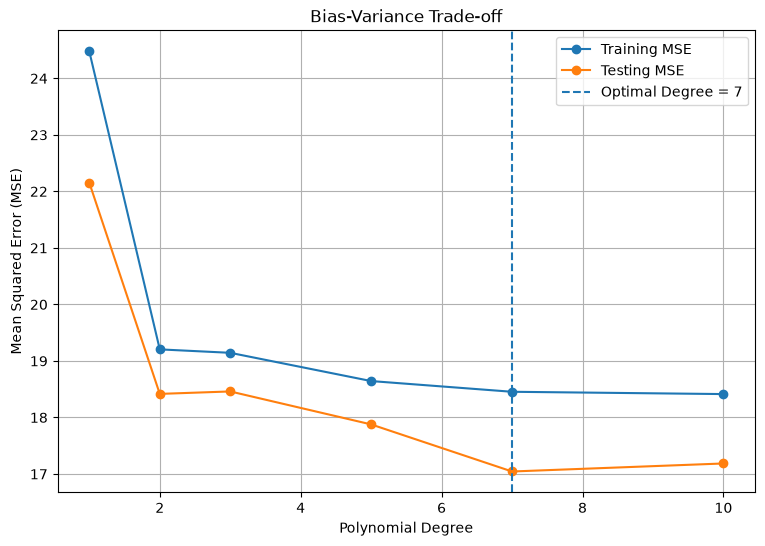

In [12]:
plt.figure(figsize=(9, 6))

plt.plot(
    degrees,
    train_mse,
    marker="o",
    label="Training MSE"
)

plt.plot(
    degrees,
    test_mse,
    marker="o",
    label="Testing MSE"
)

plt.axvline(
    optimal_degree,
    linestyle="--",
    label=f"Optimal Degree = {optimal_degree}"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Bias-Variance Trade-off")

plt.legend()
plt.grid(True)

plt.show()

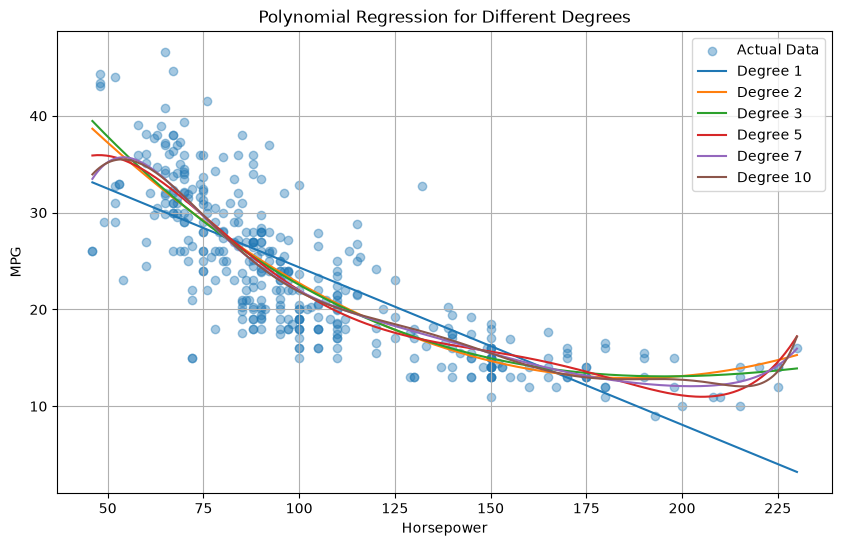

In [13]:
# Sort X values for smooth curves
X_plot = np.linspace(
    X["horsepower"].min(),
    X["horsepower"].max(),
    300
).reshape(-1, 1)

plt.figure(figsize=(10, 6))

# Original data
plt.scatter(
    X,
    y,
    alpha=0.4,
    label="Actual Data"
)

for degree in degrees:

    poly = models[degree]["poly"]
    scaler = models[degree]["scaler"]
    model = models[degree]["model"]

    # Transform X
    X_poly = poly.transform(X_plot)

    # Scale
    X_scaled = scaler.transform(X_poly)

    # Predict
    y_plot = model.predict(X_scaled)

    # Plot curve
    plt.plot(
        X_plot,
        y_plot,
        label=f"Degree {degree}"
    )

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Polynomial Regression for Different Degrees")

plt.legend()
plt.grid(True)

plt.show()

In [14]:
print(f"Optimal Polynomial Degree = {optimal_degree}")
print(f"Minimum Test MSE = {test_mse[optimal_index]:.4f}")
print(f"Test R² = {test_r2[optimal_index]:.4f}")

print("\nInterpretation:")

if optimal_degree == 1:
    print("Degree 1 shows underfitting because the model is too simple.")
elif optimal_degree in [2, 3]:
    print("Degree 2/3 provides a good balance between bias and variance.")
else:
    print("Higher polynomial degree provides better training fit but may increase variance.")

Optimal Polynomial Degree = 7
Minimum Test MSE = 17.0438
Test R² = 0.6661

Interpretation:
Higher polynomial degree provides better training fit but may increase variance.


In [15]:
print("\nPlaintext\n")

print("Degree  Train MSE      Test MSE       Test R²")
print("-" * 53)

for i, degree in enumerate(degrees):

    if degree == 1:
        remark = "(Underfitting: High Bias)"
    elif degree == 2:
        remark = "(Optimal Trade-Off)"
    elif degree == 10:
        remark = "(Overfitting: High Variance)"
    else:
        remark = ""

    print(
        f"{degree:<8}"
        f"{train_mse[i]:<15.4f}"
        f"{test_mse[i]:<15.4f}"
        f"{test_r2[i]:<15.4f}"
        f"{remark}"
    )


Plaintext

Degree  Train MSE      Test MSE       Test R²
-----------------------------------------------------
1       24.4752        22.1532        0.5660         (Underfitting: High Bias)
2       19.2046        18.4170        0.6392         (Optimal Trade-Off)
3       19.1438        18.4603        0.6383         
5       18.6440        17.8770        0.6497         
7       18.4543        17.0438        0.6661         
10      18.4137        17.1858        0.6633         (Overfitting: High Variance)
